# Tutoriel U-Net : segmentation d'échographies du sein et comparaison de cinq architectures

**TP 2 — Notebook de génération des architectures (U-Net et variantes)**

Ce notebook reprend le tutoriel fourni (*Biomedical Image Segmentation with U-Net*, jeu de données *Breast Ultrasound Images* de Kaggle) et le prolonge en trois temps :

1. **Compléter le U-Net du tutoriel** : les `...` sont remplacés par les bonnes valeurs, et le code demandé pour **visualiser les cartes de caractéristiques de chaque couche** (4 blocs d'encodeur, espace latent, 4 blocs de décodeur) est écrit à l'endroit indiqué ;
2. **Générer d'autres architectures** avec le même squelette, en ne changeant qu'un ingrédient à la fois : sans connexions de saut, version allégée, avec *BatchNorm* et *Dropout*, et *Attention U-Net* ;
3. **Comparer les cinq modèles** dans les mêmes conditions (mêmes données, même découpage, même optimiseur, mêmes 40 époques) : nombre de paramètres, coût de calcul, IoU, Dice, temps d'entraînement et exemples de prédictions.

| Modèle | Ce qui change par rapport au U-Net de référence |
|---|---|
| **A. U-Net (référence)** | Le modèle du tutoriel, une fois complété |
| **B. Sans connexions de saut** | On supprime les `concatenate` : simple encodeur-décodeur |
| **C. U-Net léger** | 16 filtres de base au lieu de 64 (environ 16 fois moins de paramètres) |
| **D. U-Net + BatchNorm + Dropout** | Normalisation par lots après chaque convolution et dropout de 0,1 après chaque bloc |
| **E. Attention U-Net** | Une *attention gate* filtre chaque connexion de saut avant la concaténation |

> **À propos de l'exécution.** Les cellules d'analyse théorique (nombre de paramètres et de multiplications-accumulations de chaque architecture, schémas) n'utilisent que NumPy et Matplotlib : elles ont été exécutées et leurs sorties sont conservées. Les cellules qui demandent TensorFlow et le jeu de données (entraînement, évaluation, cartes de caractéristiques) sont complètes mais **n'ont pas été lancées** dans l'environnement de préparation (ni TensorFlow, ni accès à Kaggle). Sur **Google Colab** avec un GPU (*Exécution → Modifier le type d'exécution → GPU*), un « Exécuter tout » remplit les sorties ; comptez environ 15 à 40 minutes pour les cinq entraînements selon le GPU.

## 0. Préparation de l'environnement

In [1]:
import os, time, shutil, random
import matplotlib.pyplot as plt
import cv2
import numpy as np
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate,
                                     BatchNormalization, Activation, Dropout, Add, Multiply)
from tensorflow.keras.models import Model

SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__)
print("GPU détecté :", tf.config.list_physical_devices("GPU") or "aucun (l'entraînement sera lent)")

TensorFlow 2.21.0
GPU détecté : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Récupération des données

Le tutoriel attend deux dossiers, `Cancer/malignant` et `Cancer/benign`, qui contiennent chaque image échographique et son ou ses masques (fichiers dont le nom contient `mask`). La cellule suivante les crée automatiquement à partir du jeu de données Kaggle si ces dossiers n'existent pas encore ; la classe `normal`, qui n'a pas de lésion à segmenter, est volontairement écartée.

Si le téléchargement automatique échoue (il demande un accès à Kaggle), téléchargez l'archive à la main depuis le lien du tutoriel, décompressez-la, puis copiez les dossiers `benign` et `malignant` du dossier `Dataset_BUSI_with_GT` dans un dossier `Cancer`.

In [2]:
def find_dirs(root, names):
    # Cherche dans toute l'arborescence les dossiers portant l'un des noms demandés.
    found = {}
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if d in names and d not in found:
                found[d] = os.path.join(dirpath, d)
    return found

if not (os.path.isdir("Cancer/benign") and os.path.isdir("Cancer/malignant")):
    try:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
        root = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")
        dirs = find_dirs(root, {"benign", "malignant"})
        os.makedirs("Cancer", exist_ok=True)
        for cls, src in dirs.items():
            shutil.copytree(src, os.path.join("Cancer", cls), dirs_exist_ok=True)
        print("Données prêtes dans le dossier Cancer :", sorted(os.listdir("Cancer")))
    except Exception as err:
        print("Téléchargement automatique impossible :", err)
        print("Placez les dossiers benign et malignant dans ./Cancer/ puis relancez la cellule suivante.")
else:
    print("Dossier Cancer déjà présent :", sorted(os.listdir("Cancer")))

Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
Données prêtes dans le dossier Cancer : ['benign', 'malignant']


## 1. Chargement et préparation des images

Le code de chargement est celui du tutoriel. Chaque image est redimensionnée en 128×128, passée en niveaux de gris et normalisée dans [0, 1]. Quand une image possède plusieurs masques (plusieurs lésions), ils sont fusionnés en un seul masque binaire.

Une seule modification par rapport au tutoriel : le découpage entraînement/validation reçoit une graine (`random_state=42`). Sans elle, chaque exécution produit un découpage différent, et comparer cinq modèles sur des validations différentes n'aurait aucun sens.

In [3]:
folder_paths = ["Cancer/malignant", "Cancer/benign"] # Paths to the 2 folders

size = 128 # Input size: 128x128

images = [] # Empty list to store the original images in
masks = [] # Empty list to store the masks in

found_mask = False # This flag helps us handle multiple masks for the same image
# Loop through both folders
for folder_path in folder_paths:
    # Loop through all files in the current folder (sorted for consistency)
    for file_path in sorted(glob(folder_path + "/*")):
        # Load and resize the image
        img = cv2.imread(file_path)
        img = cv2.resize(img, (size, size)) # Resize image to 128×128
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) # Convert RGB to grayscale
        img = img / 255.0 # Normalize to [0,1]

        if "mask" in file_path: # Checks if the filename contains "mask"
            if found_mask:
                # Combine with the previous mask
                masks[-1] += img
                # Ensure binary output (0 or 1)
                masks[-1] = np.where(masks[-1] > 0.5, 1.0, 0.0)
            else:
                masks.append(img) # Adds the first mask to the list
                found_mask = True
        else:
            images.append(img) # Adds original image to the list
            found_mask = False

# Convert lists to NumPy arrays
X = np.array(images) # Create an array of all original images
y = np.array(masks) # Create an array of all masked imaged (Ground truth)

X = np.expand_dims(X, -1)
y = np.expand_dims(y, -1)

print(f"X shape: {X.shape} | y shape: {y.shape}")
# Split images into training and validation (graine fixe pour une comparaison équitable)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=SEED)
print(f"Entraînement : {len(X_train)} images | Validation : {len(X_val)} images")
print(f"Part moyenne de pixels « lésion » dans les masques : {y.mean():.1%}")

X shape: (647, 128, 128, 1) | y shape: (647, 128, 128, 1)
Entraînement : 582 images | Validation : 65 images
Part moyenne de pixels « lésion » dans les masques : 9.4%


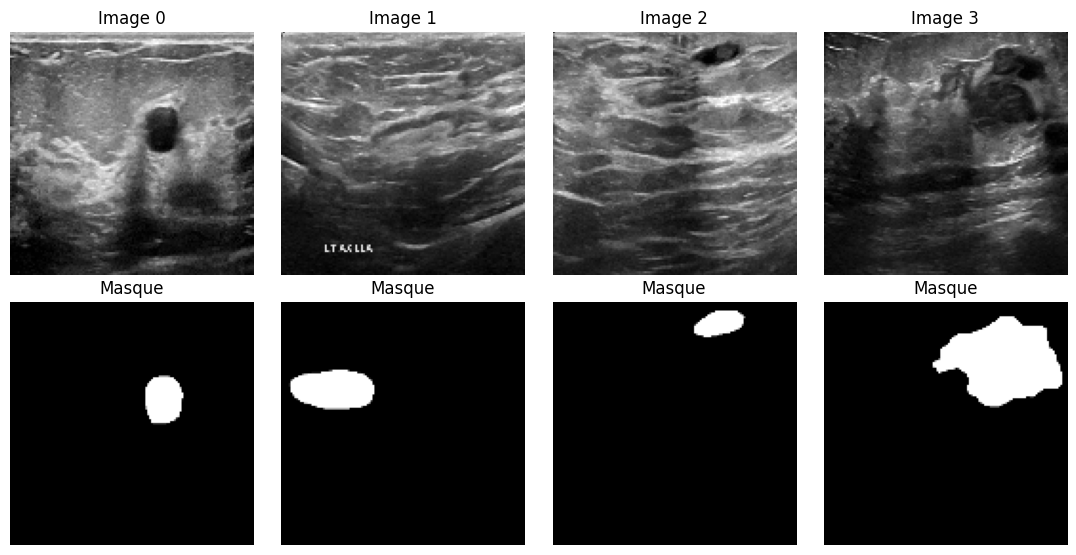

In [4]:
# Quelques exemples : image échographique et masque de la lésion
fig, axs = plt.subplots(2, 4, figsize=(11, 5.6))
for k in range(4):
    axs[0, k].imshow(X_train[k], cmap="gray"); axs[0, k].set_title(f"Image {k}"); axs[0, k].axis("off")
    axs[1, k].imshow(y_train[k], cmap="gray");  axs[1, k].set_title("Masque");     axs[1, k].axis("off")
plt.tight_layout(); plt.show()

## 2. Le U-Net du tutoriel, complété

### 2.1 Outil de visualisation des cartes de caractéristiques

La consigne demande de visualiser les cartes de caractéristiques (*feature maps*) de chaque couche du modèle. Une carte de caractéristiques est la sortie d'un bloc de convolutions : un tableau de taille `hauteur × largeur × canaux`, où chaque canal est une « image » qui répond à un motif particulier.

Le principe retenu est le suivant. À chacun des emplacements marqués `#votre code pour visualiser...` dans la construction du modèle, on **enregistre le tenseur de sortie du bloc** dans un dictionnaire ordonné. Une fois le modèle construit, on crée un second modèle (*extracteur*) qui partage les mêmes couches mais renvoie tous ces tenseurs : un seul passage d'une image donne alors les neuf cartes (4 encodeur, espace latent, 4 décodeur). La fonction ci-dessous les affiche : huit canaux régulièrement espacés par couche, puis une ligne de synthèse avec la moyenne des canaux de chaque couche.

In [5]:
def plot_feature_maps(extractor, layer_names, image, n_maps=8):
    # image : tableau (H, W, 1). Affiche, pour chaque couche enregistrée, n_maps canaux
    # régulièrement espacés, puis une ligne de synthèse (moyenne des canaux de chaque couche).
    outputs = extractor.predict(image[np.newaxis], verbose=0)
    if not isinstance(outputs, (list, tuple)):
        outputs = [outputs]

    for name, fmap in zip(layer_names, outputs):
        fmap = fmap[0]                                   # on retire la dimension du lot
        h, w, c = fmap.shape
        idx = np.linspace(0, c - 1, min(n_maps, c)).astype(int)
        fig, axs = plt.subplots(1, len(idx), figsize=(2 * len(idx), 2.4))
        for ax, k in zip(np.atleast_1d(axs), idx):
            ax.imshow(fmap[:, :, k], cmap="viridis")
            ax.set_title(f"canal {k}", fontsize=8); ax.axis("off")
        fig.suptitle(f"{name} : {h}×{w}×{c} ({len(idx)} canaux affichés sur {c})", fontsize=10)
        plt.tight_layout(); plt.show()

    fig, axs = plt.subplots(1, len(outputs) + 1, figsize=(2 * (len(outputs) + 1), 2.6))
    axs[0].imshow(image[:, :, 0], cmap="gray"); axs[0].set_title("Entrée", fontsize=8); axs[0].axis("off")
    for ax, name, fmap in zip(axs[1:], layer_names, outputs):
        ax.imshow(fmap[0].mean(axis=-1), cmap="magma")
        ax.set_title(name, fontsize=7); ax.axis("off")
    fig.suptitle("Synthèse : moyenne des canaux de chaque couche", fontsize=10)
    plt.tight_layout(); plt.show()

### 2.2 Construction du modèle

Les `...` du tutoriel se déduisent de la figure du U-Net ci-dessous : le nombre de filtres double à chaque étape de l'encodeur (64, 128, 256, 512), atteint 1024 dans l'espace latent, puis est divisé par deux à chaque étape du décodeur (512, 256, 128, 64). Les convolutions font 3×3, les max-poolings 2×2, les convolutions transposées 2×2 avec un pas de 2, et la couche finale est une convolution 1×1 à **un seul filtre** avec une activation sigmoïde, puisque le masque est binaire (lésion ou fond).

![unet.png](attachment:unet.png)

In [6]:
# Build the U-Net
# Les tenseurs à visualiser sont enregistrés dans ce dictionnaire, dans l'ordre du réseau.
feature_tensors = {}

input_layer = Input(shape=(size, size, 1))
conv1 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(input_layer)
conv1 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv1)
pool1 = MaxPooling2D((2, 2))(conv1)

# Cartes des caractéristiques de la couche 1 de l'encodeur (sortie du bloc, avant le pooling)
feature_tensors["Encodeur 1 (64 filtres)"] = conv1

# Second encoder block
conv2 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool1)
conv2 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv2)
pool2 = MaxPooling2D((2, 2))(conv2)

# Cartes des caractéristiques de la couche 2 de l'encodeur
feature_tensors["Encodeur 2 (128 filtres)"] = conv2

# Third encoder block
conv3 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool2)
conv3 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv3)
pool3 = MaxPooling2D((2, 2))(conv3)

# Cartes des caractéristiques de la couche 3 de l'encodeur
feature_tensors["Encodeur 3 (256 filtres)"] = conv3

# Fourth encoder block
conv4 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool3)
conv4 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv4)
pool4 = MaxPooling2D((2, 2))(conv4)

# Cartes des caractéristiques de la couche 4 de l'encodeur
feature_tensors["Encodeur 4 (512 filtres)"] = conv4
# --- Bottleneck ---
bottleneck = Conv2D(1024, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool4)
bottleneck = Conv2D(1024, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(bottleneck)

# Cartes des caractéristiques de la couche espace latente
feature_tensors["Espace latent (1024 filtres)"] = bottleneck
# First decoder block
upconv1 = Conv2DTranspose(512, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(bottleneck)
concat1 = concatenate([upconv1, conv4])
conv5 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat1)
conv5 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv5)

# Cartes des caractéristiques de la couche 1 du decodeur
feature_tensors["Décodeur 1 (512 filtres)"] = conv5

# Second decoder block
upconv2 = Conv2DTranspose(256, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv5)
concat2 = concatenate([upconv2, conv3])
conv6 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat2)
conv6 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv6)

# Cartes des caractéristiques de la couche 2 du decodeur
feature_tensors["Décodeur 2 (256 filtres)"] = conv6

# Third decoder block
upconv3 = Conv2DTranspose(128, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv6)
concat3 = concatenate([upconv3, conv2])
conv7 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat3)
conv7 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv7)

# Cartes des caractéristiques de la couche 3 du decodeur
feature_tensors["Décodeur 3 (128 filtres)"] = conv7
# Fourth decoder block
upconv4 = Conv2DTranspose(64, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv7)
concat4 = concatenate([upconv4, conv1])
conv8 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat4)
conv8 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv8)

# Cartes des caractéristiques de la couche 4 du decodeur
feature_tensors["Décodeur 4 (64 filtres)"] = conv8
# --- Output layer ---
output_layer = Conv2D(1, (1, 1), activation="sigmoid", padding="same")(conv8)

# --- Model creation ---
model = Model(inputs=input_layer, outputs=output_layer)
model.summary()

# Extracteur : même entrée, mais renvoie les neuf cartes enregistrées ci-dessus
feature_names = list(feature_tensors.keys())
feature_extractor = Model(inputs=input_layer, outputs=list(feature_tensors.values()))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,030,593 (118.37 MB)

 Trainable params: 31,030,593 (118.37 MB)

 Non-trainable params: 0 (0.00 B)

Avant d'entraîner, on peut déjà regarder les cartes produites par le réseau **avec ses poids initiaux** (He normal, tirés au hasard). Elles ne détectent encore rien de précis : ce sont des filtres aléatoires appliqués à l'image. Cette vue servira de point de comparaison après l'entraînement.

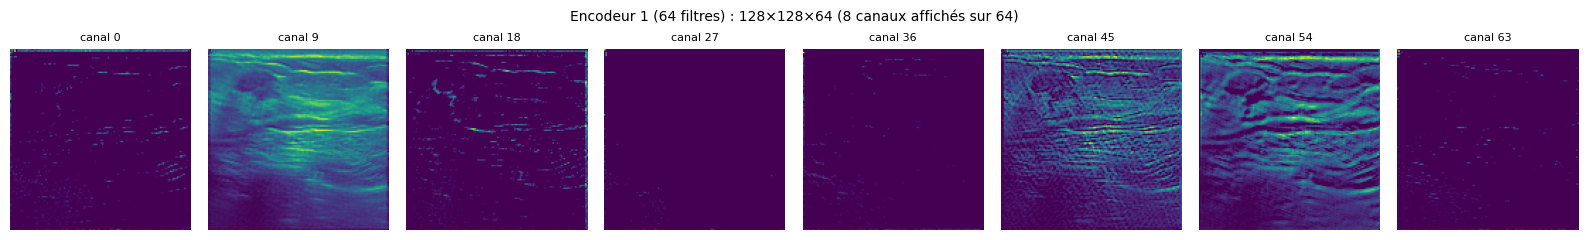

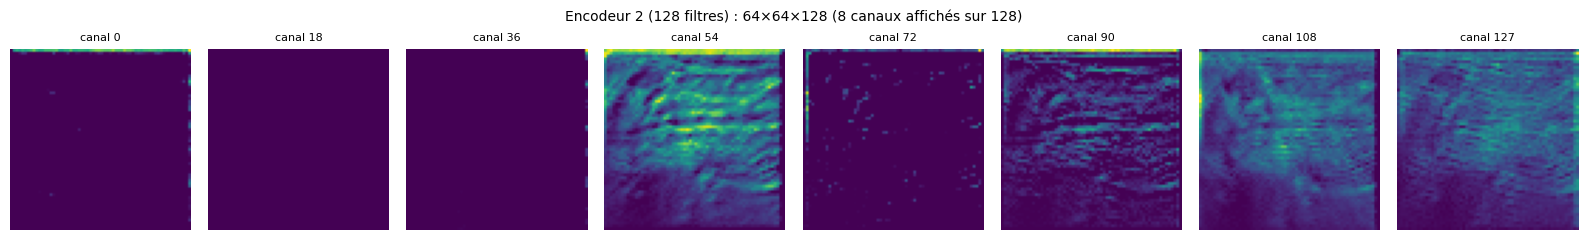

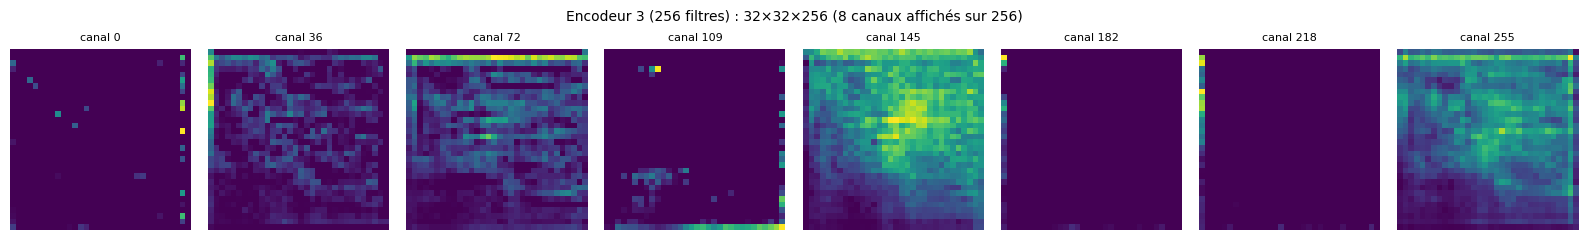

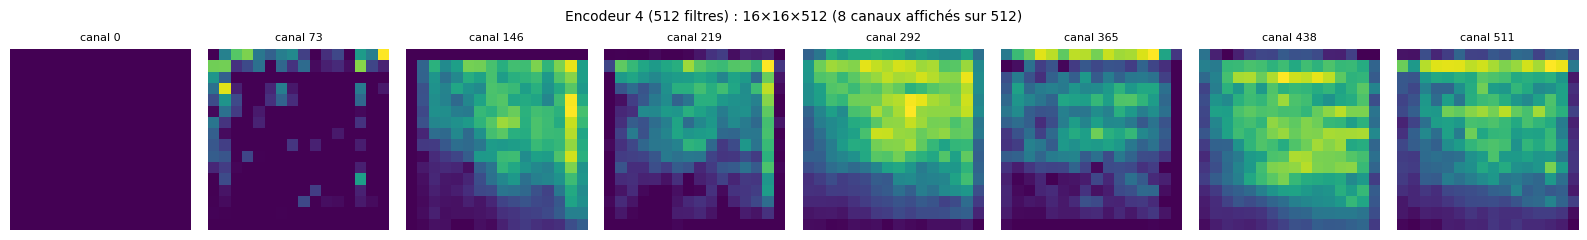

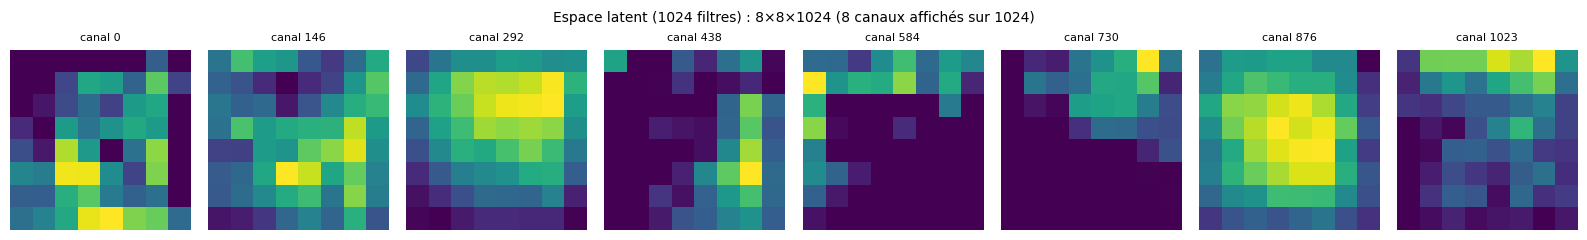

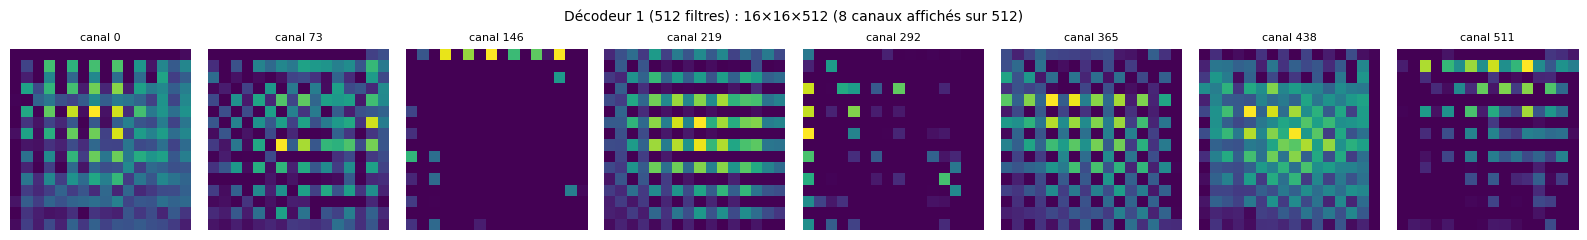

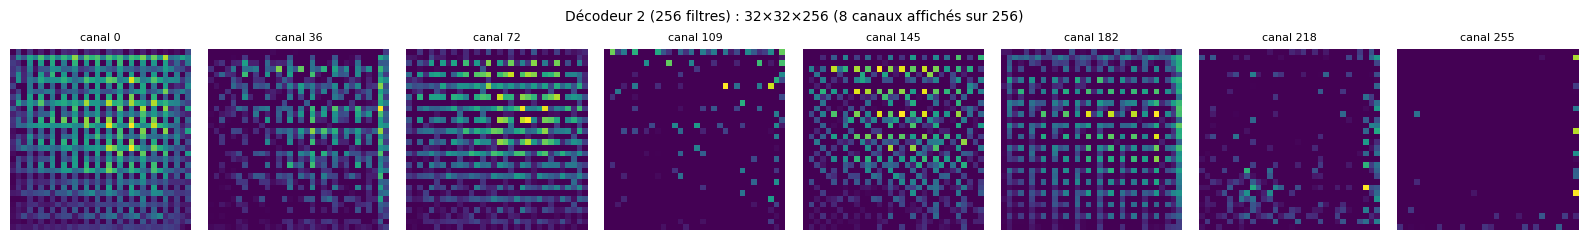

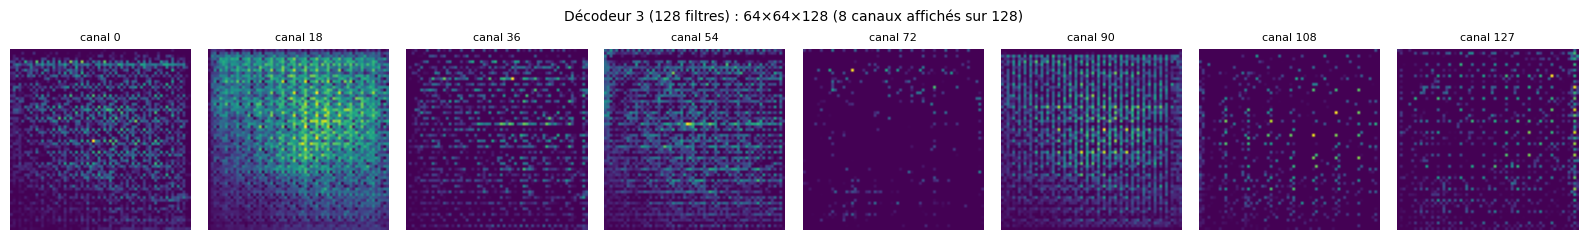

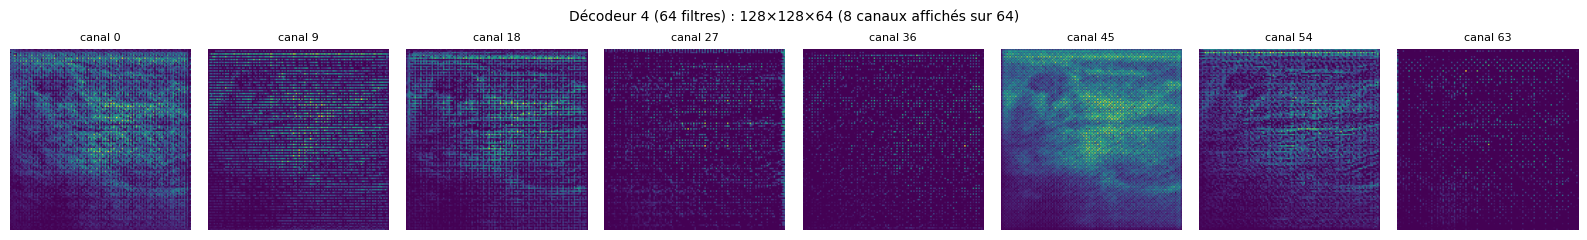

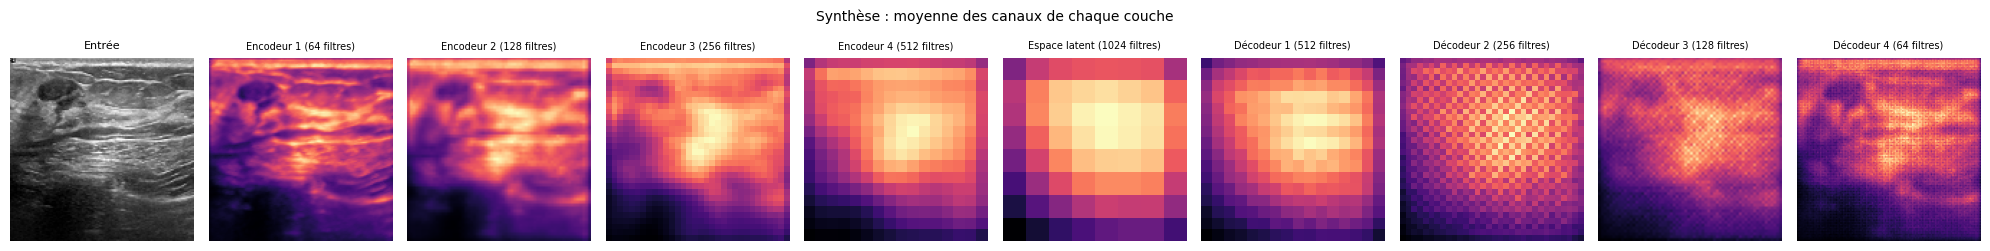

In [7]:
sample = X_val[6]                    # une image de validation ; essayez d'autres indices
plot_feature_maps(feature_extractor, feature_names, sample, n_maps=8)

### 2.3 Entraînement et évaluation (cellules du tutoriel)

Les réglages sont ceux du tutoriel : perte d'entropie croisée binaire, optimiseur Adam, 40 époques. On mesure en plus la durée de l'entraînement, qui servira à la comparaison.

In [8]:
# Compile and train the model
model.compile(loss="binary_crossentropy", optimizer="Adam", metrics=["accuracy"])
t0 = time.time()
history_A = model.fit(X_train, y_train, epochs = 40, validation_data = (X_val,y_val),verbose=1)
train_time_A = time.time() - t0
print(f"Durée de l'entraînement : {train_time_A / 60:.1f} min")

Epoch 1/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 135s 4s/step - accuracy: 0.8239 - loss: 0.4828 - val_accuracy: 0.9061 - val_loss: 0.2893
Epoch 2/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 328ms/step - accuracy: 0.9036 - loss: 0.2940 - val_accuracy: 0.9058 - val_loss: 0.2374
Epoch 3/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 327ms/step - accuracy: 0.9047 - loss: 0.2483 - val_accuracy: 0.9058 - val_loss: 0.2376
Epoch 4/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 332ms/step - accuracy: 0.9090 - loss: 0.2294 - val_accuracy: 0.9122 - val_loss: 0.2180
Epoch 5/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step - accuracy: 0.9181 - loss: 0.2129 - val_accuracy: 0.9203 - val_loss: 0.2080
Epoch 6/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 332ms/step - accuracy: 0.9147 - loss: 0.2168 - val_accuracy: 0.9189 - val_loss: 0.2126
Epoch 7/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 334ms/step - accuracy: 0.9252 - loss: 0.1956 - val_accuracy: 0.9226 - val_loss: 0.1982
Epoch 8/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step - accuracy: 0.9240 - loss: 0.1971 - val_accuracy: 0.9

In [9]:
# Compute IoU
from sklearn.metrics import jaccard_score
# Compute predicted mask
pred=model.predict(X_val,verbose=1)
pred = (pred > 0.5).astype(int) # binarize
y_true = y_val.astype(int)
# Compute IoU based on flatten predictions and ground truths
iou = jaccard_score(pred.flatten(), y_true.flatten())
print(f" IoU (Jaccard Score): {iou:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 507ms/step
 IoU (Jaccard Score): 0.5289


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


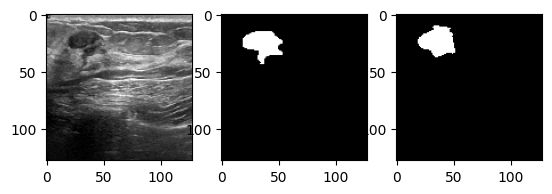

In [10]:
# Plot
i=6 # Try other values
plt.subplot(1, 3, 1)
plt.imshow(X_val[i],cmap="gray")
plt.subplot(1, 3, 2)
plt.imshow(y_val[i],cmap="gray")
plt.subplot(1, 3, 3)
pred=model.predict(np.expand_dims(X_val[i], axis=0),verbose=1)[0]
pred = (pred > 0.5) # binarize
plt.imshow(pred,cmap="gray")

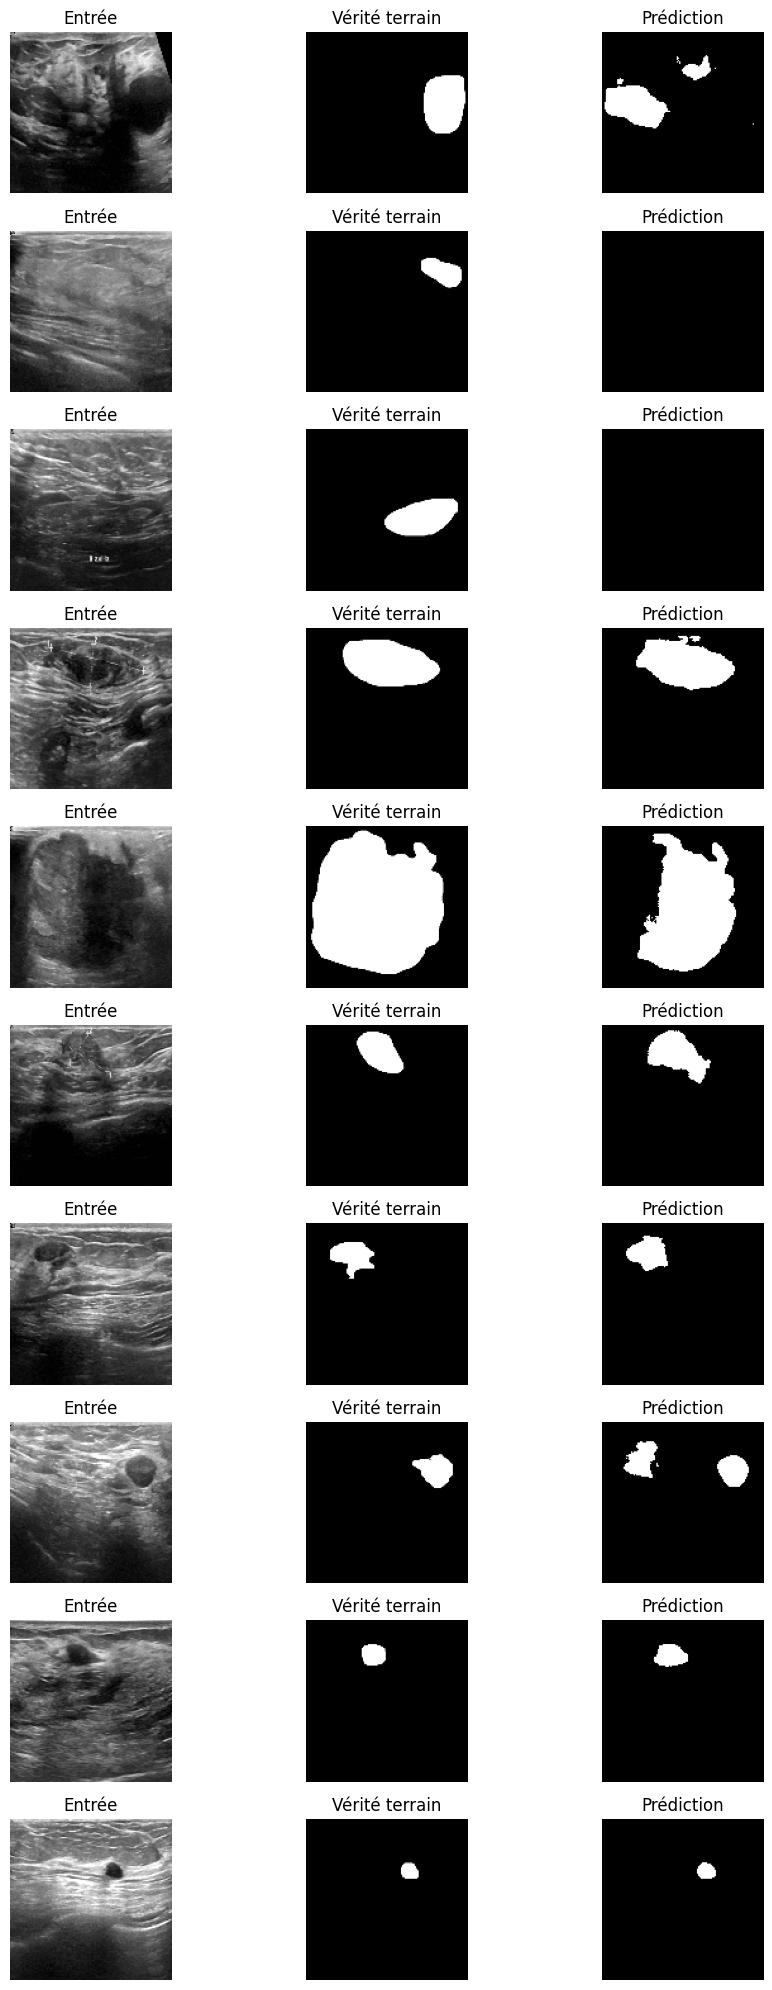

In [11]:
n = 10
plt.figure(figsize=(10, n * 2))

for i in range(n):
    # Image d'entrée
    plt.subplot(n, 3, 3*i + 1)
    plt.imshow(X_val[i], cmap='gray')
    plt.title("Entrée")
    plt.axis('off')

    # Masque réel
    plt.subplot(n, 3, 3*i + 2)
    plt.imshow(y_val[i], cmap='gray')
    plt.title("Vérité terrain")
    plt.axis('off')

    # Prédiction
    pred = model.predict(np.expand_dims(X_val[i], axis=0), verbose=0)[0]
    pred = (pred > 0.5)

    plt.subplot(n, 3, 3*i + 3)
    plt.imshow(pred, cmap='gray')
    plt.title("Prédiction")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 2.4 Cartes de caractéristiques après entraînement

On relance la visualisation sur la même image. Ce que l'on peut chercher à observer : dans les premiers blocs de l'encodeur, des cartes proches de l'image (contours, textures, zones sombres) ; plus profond, des cartes de plus en plus grossières et abstraites, où la lésion n'est plus qu'une tache ; dans le décodeur, une résolution qui remonte et des cartes qui se concentrent sur la zone de la lésion.

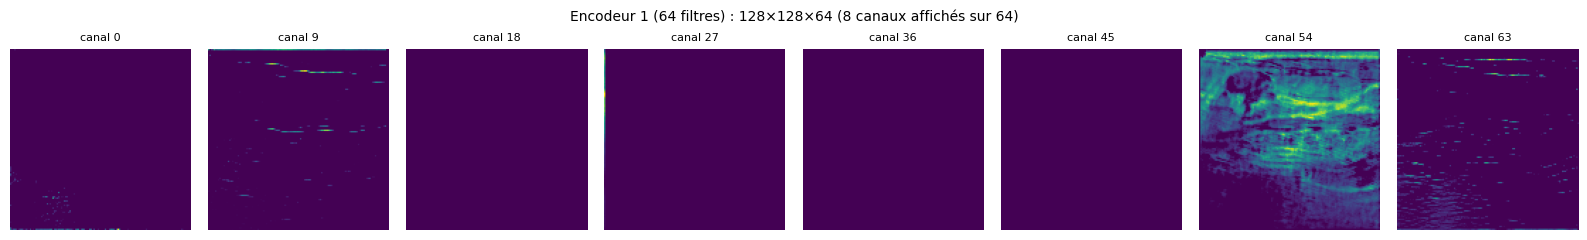

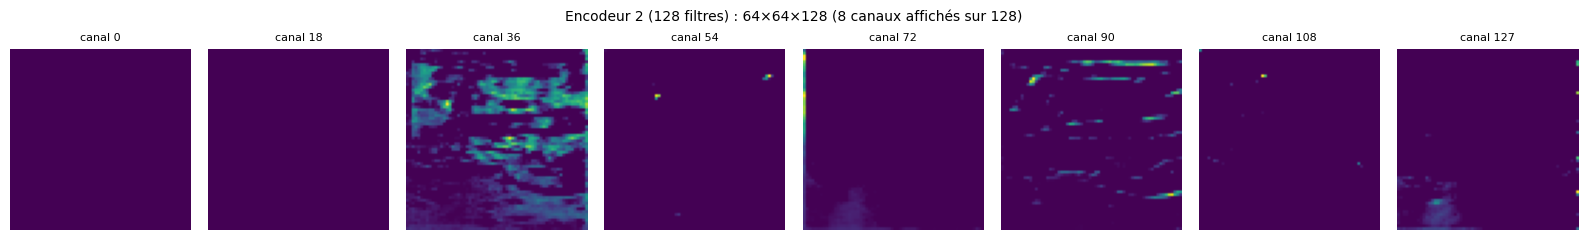

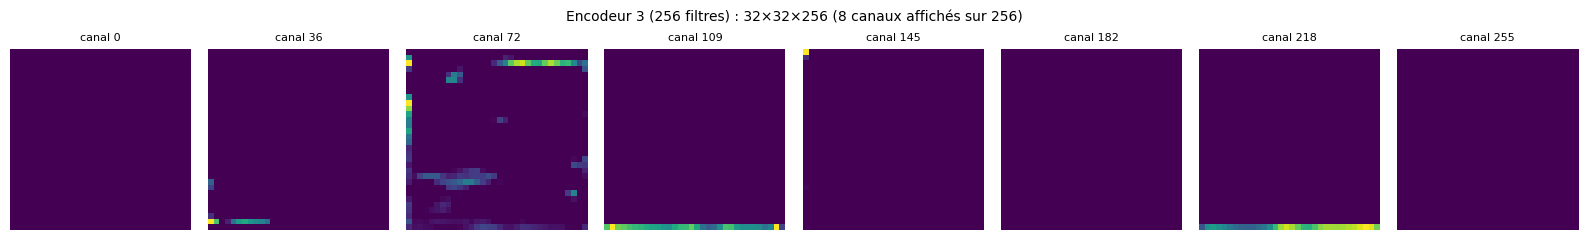

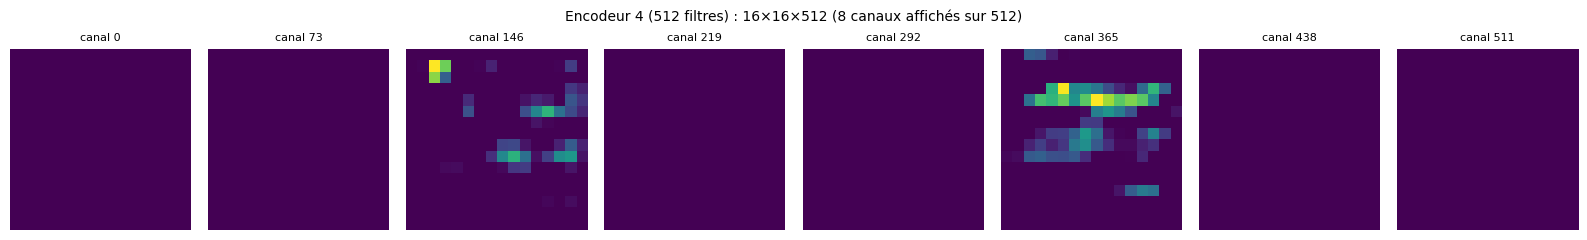

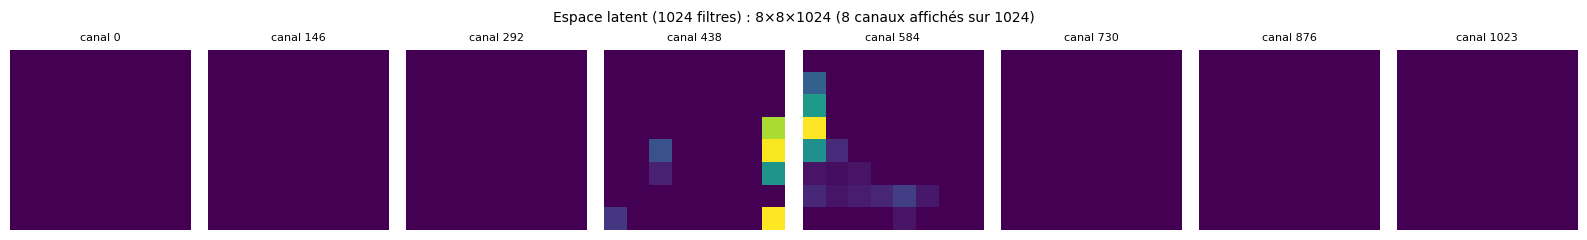

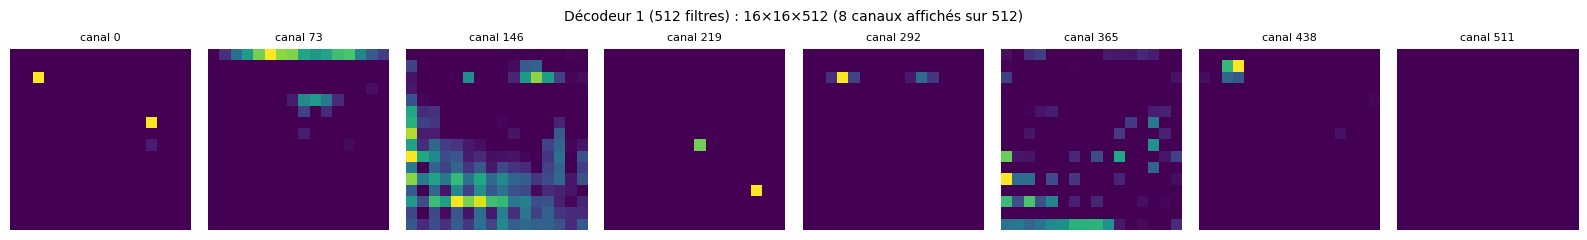

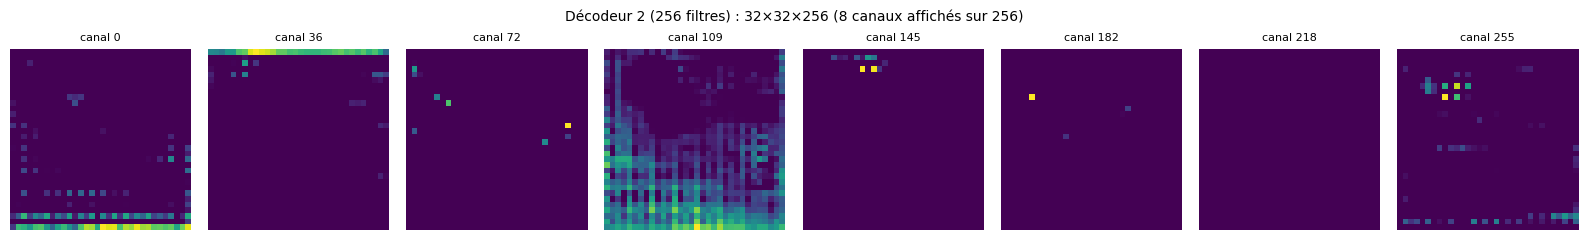

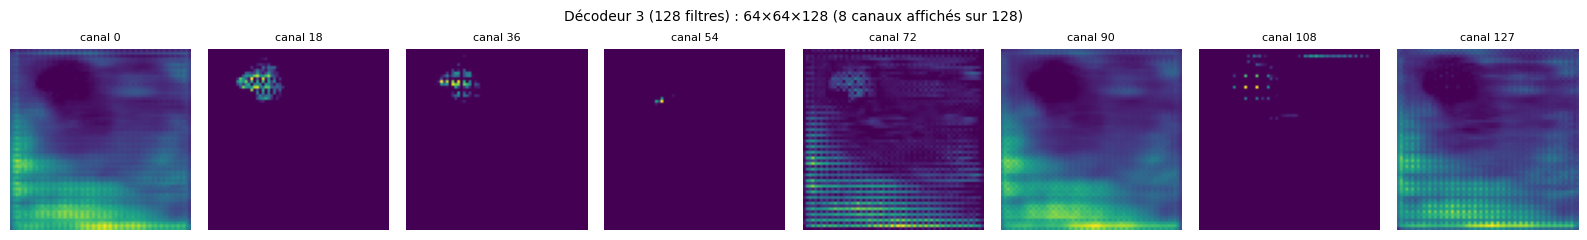

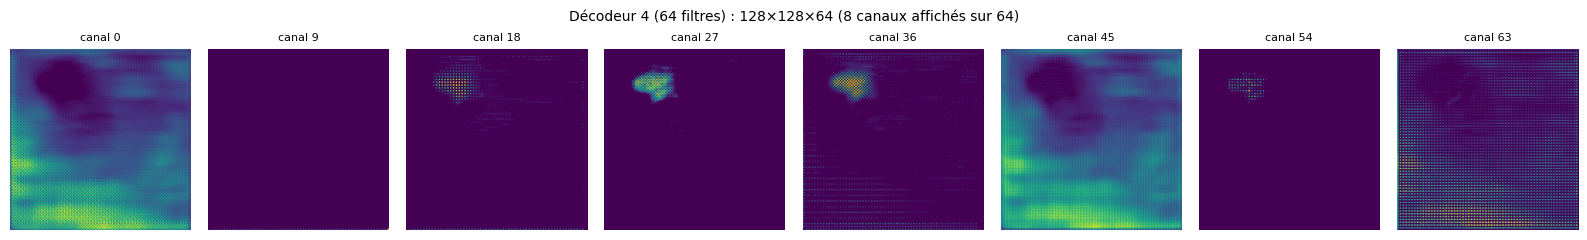

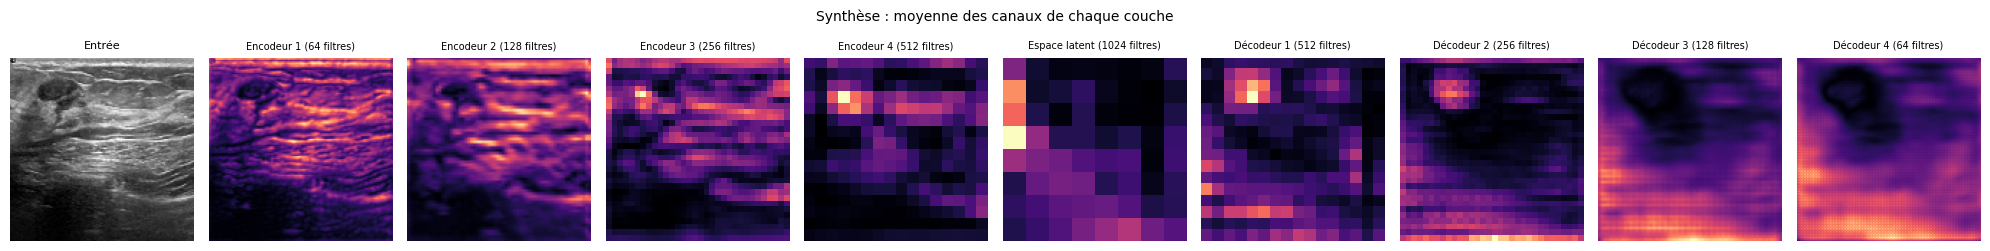

In [12]:
plot_feature_maps(feature_extractor, feature_names, sample, n_maps=8)

## 3. Générer les autres architectures

Pour comparer proprement, les quatre variantes sont produites par **une seule fonction de construction**, `build_unet`, qui reprend le squelette du tutoriel (convolutions 3×3 « same », initialisation He normal, max-pooling 2×2, convolutions transposées 2×2) et expose cinq réglages : le nombre de filtres de base, la profondeur, la présence des connexions de saut, la normalisation par lots / le dropout, et les *attention gates*.

On commence par décrire les cinq architectures dans un dictionnaire, ce qui permet de **calculer à la main** leurs nombres de paramètres et de multiplications-accumulations avant tout entraînement. Cette partie n'utilise que du calcul simple : elle a été exécutée.

In [13]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

# Description des cinq architectures. Une seule différence à la fois par rapport à A.
VARIANTS = {
    "A. U-Net (référence)":            dict(uid="unet_A", base=64, depth=4, skip=True,  batchnorm=False, dropout=0.0, attention=False),
    "B. Sans connexions de saut":      dict(uid="unet_B", base=64, depth=4, skip=False, batchnorm=False, dropout=0.0, attention=False),
    "C. U-Net léger (16 filtres)":     dict(uid="unet_C", base=16, depth=4, skip=True,  batchnorm=False, dropout=0.0, attention=False),
    "D. U-Net + BatchNorm + Dropout":  dict(uid="unet_D", base=64, depth=4, skip=True,  batchnorm=True,  dropout=0.1, attention=False),
    "E. Attention U-Net":              dict(uid="unet_E", base=64, depth=4, skip=True,  batchnorm=False, dropout=0.0, attention=True),
}
for name, cfg in VARIANTS.items():
    print(f"{name:<34}", {k: v for k, v in cfg.items() if k != "uid"})

A. U-Net (référence)               {'base': 64, 'depth': 4, 'skip': True, 'batchnorm': False, 'dropout': 0.0, 'attention': False}
B. Sans connexions de saut         {'base': 64, 'depth': 4, 'skip': False, 'batchnorm': False, 'dropout': 0.0, 'attention': False}
C. U-Net léger (16 filtres)        {'base': 16, 'depth': 4, 'skip': True, 'batchnorm': False, 'dropout': 0.0, 'attention': False}
D. U-Net + BatchNorm + Dropout     {'base': 64, 'depth': 4, 'skip': True, 'batchnorm': True, 'dropout': 0.1, 'attention': False}
E. Attention U-Net                 {'base': 64, 'depth': 4, 'skip': True, 'batchnorm': False, 'dropout': 0.0, 'attention': True}


### 3.1 Comptage des paramètres et du coût de calcul

Les formules suivent exactement la construction décrite plus haut :

- une convolution $k\times k$ de $c_{in}$ vers $c_{out}$ canaux porte $k^2\,c_{in}\,c_{out}$ poids, plus $c_{out}$ biais (pas de biais quand elle est suivie d'une *BatchNorm*) ;
- une *BatchNorm* ajoute 4 valeurs par canal (deux apprises, deux statistiques mobiles) ;
- une convolution transposée 2×2 de $c_{in}$ vers $c_{out}$ canaux porte $4\,c_{in}\,c_{out} + c_{out}$ paramètres ;
- une *attention gate* à $c_i = c/2$ canaux intermédiaires ajoute trois convolutions 1×1 : $(c\,c_i + c_i) + (c\,c_i + c_i) + (c_i + 1)$ paramètres.

Le coût de calcul est exprimé en **GMACs** (milliards de multiplications-accumulations) pour **une** image 128×128.

In [14]:
def conv_params(cin, cout, k=3, bias=True):
    return k * k * cin * cout + (cout if bias else 0)

def block_params(cin, f, bn):
    # Un bloc = deux convolutions 3x3 (+ deux BatchNorm si bn)
    p = conv_params(cin, f, bias=not bn) + conv_params(f, f, bias=not bn)
    return p + (2 * 4 * f if bn else 0)

def count_params(base, depth, skip, batchnorm, attention, in_ch=1, **_):
    total, c = 0, in_ch
    for d in range(depth):                               # encodeur
        f = base * 2 ** d
        total += block_params(c, f, batchnorm); c = f
    f = base * 2 ** depth                                # espace latent
    total += block_params(c, f, batchnorm); c = f
    for d in reversed(range(depth)):                     # décodeur
        f = base * 2 ** d
        total += 4 * c * f + f                           # convolution transposée 2x2
        if attention:
            ci = max(f // 2, 1)
            total += (f * ci + ci) + (f * ci + ci) + (ci + 1)
        total += block_params(2 * f if skip else f, f, batchnorm); c = f
    return total + c * 1 + 1                             # convolution 1x1 finale

def count_macs(base, depth, skip, batchnorm, attention, in_ch=1, H=128, **_):
    total, c, h = 0, in_ch, H
    for d in range(depth):
        f = base * 2 ** d
        total += h * h * (9 * c * f + 9 * f * f); c = f; h //= 2
    f = base * 2 ** depth
    total += h * h * (9 * c * f + 9 * f * f); c = f
    for d in reversed(range(depth)):
        f = base * 2 ** d; h *= 2
        total += h * h * c * f                           # convolution transposée 2x2 (stride 2)
        if attention:
            ci = max(f // 2, 1)
            total += h * h * (f * ci + f * ci + ci)
        cin = 2 * f if skip else f
        total += h * h * (9 * cin * f + 9 * f * f); c = f
    return total + h * h * c

rows = []
for name, cfg in VARIANTS.items():
    p, m = count_params(**cfg), count_macs(**cfg)
    rows.append((name, p, m))

ref_p, ref_m = rows[0][1], rows[0][2]
print(f"{'Architecture':<34}{'Paramètres':>14}{'GMACs / image':>16}{'vs A (param.)':>16}")
print("-" * 80)
for name, p, m in rows:
    print(f"{name:<34}{p:>14,}{m / 1e9:>16.2f}{p / ref_p:>15.2f}x".replace(",", " "))
print()
print("Contrôle : le U-Net de référence compte", f"{ref_p:,}".replace(",", " "), "paramètres.")
print("C'est la valeur attendue pour le U-Net classique à 64 filtres de base, 1 canal d'entrée et 1 canal de sortie.")

Architecture                          Paramètres   GMACs / image   vs A (param.)
--------------------------------------------------------------------------------
A. U-Net (référence)                  31 030 593           12.02           1.00x
B. Sans connexions de saut            27 897 153            9.61           0.90x
C. U-Net léger (16 filtres)            1 940 817            0.75           0.06x
D. U-Net + BatchNorm + Dropout        31 048 257           12.02           1.00x
E. Attention U-Net                    31 380 197           12.29           1.01x

Contrôle : le U-Net de référence compte 31 030 593 paramètres.
C'est la valeur attendue pour le U-Net classique à 64 filtres de base, 1 canal d'entrée et 1 canal de sortie.


Quelques lectures directes de ce tableau, avant même d'entraîner quoi que ce soit :

- supprimer les connexions de saut (B) **réduit** le modèle d'environ 10 % en paramètres et de 20 % en calcul, parce que les convolutions du décodeur reçoivent deux fois moins de canaux ; l'économie est réelle mais modeste, et on verra ce qu'elle coûte en précision ;
- diviser par quatre le nombre de filtres de base (C) divise le nombre de paramètres par environ 16 : les paramètres varient comme le **carré** du nombre de canaux ;
- la *BatchNorm* et le dropout (D) ajoutent très peu de paramètres (environ 18 000, soit 0,06 %) ; leur coût réel est ailleurs, dans les opérations de normalisation à chaque couche, que le décompte en multiplications-accumulations ne voit pas ;
- les *attention gates* (E) ajoutent environ 350 000 paramètres (+1,1 %) et 2 % de calcul, puisqu'elles ne contiennent que des convolutions 1×1.

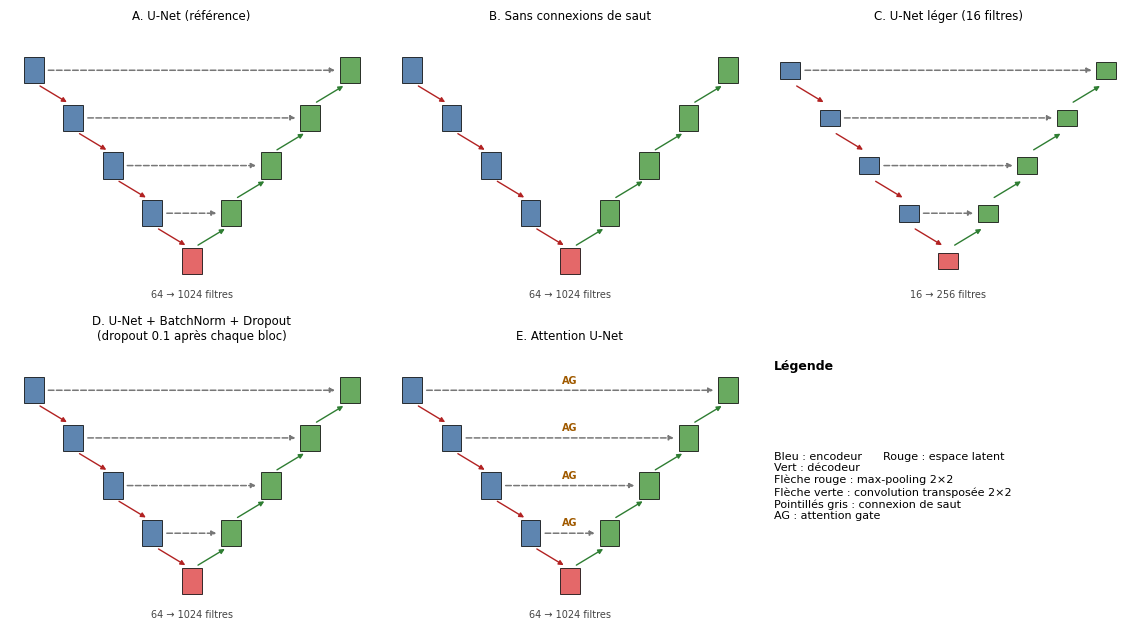

In [15]:
# Schéma des cinq architectures : ce qui change d'un modèle à l'autre
def draw_variant(ax, title, cfg):
    depth = cfg["depth"]
    ax.set_xlim(-0.6, 2 * depth + 0.6); ax.set_ylim(depth + 0.8, -0.9); ax.axis("off")
    c_enc, c_dec, c_bot = "#4c78a8", "#59a14f", "#e15759"
    def box(x, y, color, w=0.5, h=0.45):
        ax.add_patch(Rectangle((x - w / 2, y - h / 2), w, h, fc=color, ec="black", lw=0.6, alpha=0.9))
    scale = 1.0 if cfg["base"] == 64 else 0.55                       # boîtes plus petites pour le modèle léger
    for d in range(depth):
        box(d, d, c_enc, h=0.45 * scale + 0.1)
        ax.add_patch(FancyArrowPatch((d + 0.1, d + 0.3), (d + 0.9, d + 0.7), arrowstyle="-|>", mutation_scale=7, color="#b22222", lw=1))
    box(depth, depth, c_bot, h=0.45 * scale + 0.1)
    for d in reversed(range(depth)):
        x = 2 * depth - d
        box(x, d, c_dec, h=0.45 * scale + 0.1)
        ax.add_patch(FancyArrowPatch((x - 0.9, d + 0.7), (x - 0.1, d + 0.3), arrowstyle="-|>", mutation_scale=7, color="#2e7d32", lw=1))
        if cfg["skip"]:
            ax.add_patch(FancyArrowPatch((d + 0.3, d), (x - 0.3, d), arrowstyle="-|>", mutation_scale=7, color="#777777", lw=1.1, ls="--"))
            if cfg["attention"]:
                ax.text((d + x) / 2, d - 0.12, "AG", ha="center", va="bottom", fontsize=7, color="#a05a00", fontweight="bold")
    sub = f"\n(dropout {cfg['dropout']} après chaque bloc)" if cfg["dropout"] > 0 else ""
    ax.set_title(title + sub, fontsize=8.5)
    ax.text(depth, depth + 0.75, f"{cfg['base']} → {cfg['base'] * 2 ** depth} filtres", ha="center", fontsize=7, color="#444")

fig, axs = plt.subplots(2, 3, figsize=(11.5, 6.4))
for ax, (name, cfg) in zip(axs.ravel(), VARIANTS.items()):
    draw_variant(ax, name, cfg)
axs.ravel()[-1].axis("off")
axs.ravel()[-1].text(0.02, 0.92, "Légende", fontsize=9, fontweight="bold", transform=axs.ravel()[-1].transAxes)
axs.ravel()[-1].text(0.02, 0.62, "Bleu : encodeur      Rouge : espace latent\nVert : décodeur\nFlèche rouge : max-pooling 2×2\nFlèche verte : convolution transposée 2×2\nPointillés gris : connexion de saut\nAG : attention gate", fontsize=8, va="top", transform=axs.ravel()[-1].transAxes)
fig.tight_layout(); fig.savefig("fig_variantes.png", dpi=160); plt.show()

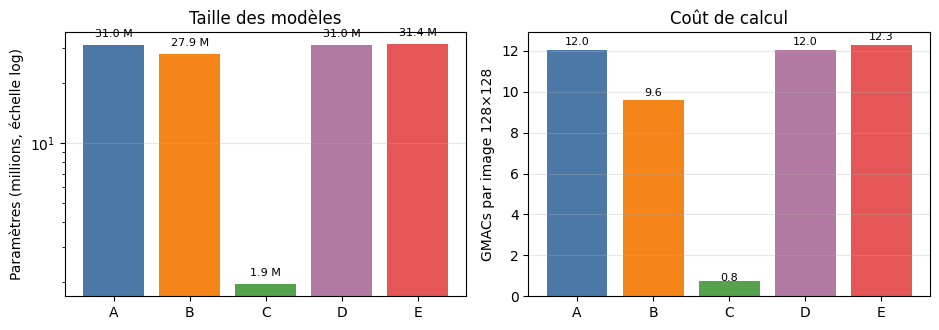

In [16]:
# Paramètres et coût de calcul des cinq architectures
labels = [r[0].split(".")[0] for r in rows]
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4))
colors = ["#4c78a8", "#f58518", "#54a24b", "#b279a2", "#e45756"]
axs[0].bar(labels, [r[1] / 1e6 for r in rows], color=colors); axs[0].set_yscale("log")
axs[0].set_ylabel("Paramètres (millions, échelle log)"); axs[0].set_title("Taille des modèles")
for i, r in enumerate(rows): axs[0].text(i, r[1] / 1e6 * 1.1, f"{r[1] / 1e6:.1f} M", ha="center", fontsize=8)
axs[1].bar(labels, [r[2] / 1e9 for r in rows], color=colors)
axs[1].set_ylabel("GMACs par image 128×128"); axs[1].set_title("Coût de calcul")
for i, r in enumerate(rows): axs[1].text(i, r[2] / 1e9 * 1.02, f"{r[2] / 1e9:.1f}", ha="center", fontsize=8)
for ax in axs: ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("fig_params.png", dpi=160); plt.show()

### 3.2 La fonction de construction

La fonction ci-dessous produit n'importe laquelle des cinq architectures. Le U-Net de référence qu'elle fabrique est identique à celui de la section 2 : on le vérifie plus bas en comparant les nombres de paramètres (et en les confrontant au calcul à la main).

Deux détails d'implémentation méritent d'être signalés :

- **Dropout et BatchNorm** : quand la *BatchNorm* est active, les convolutions n'ont pas de biais (la normalisation les rend inutiles), et l'activation ReLU vient après la normalisation ; le dropout est appliqué à la fin de chaque bloc.
- **Attention gate** (Oktay et al., 2018) : pour chaque connexion de saut, on projette par une convolution 1×1 la carte de saut $x$ et le signal de contrôle $g$ (la sortie de la convolution transposée, de même taille), on les additionne, on applique une ReLU puis une convolution 1×1 et une sigmoïde. On obtient un coefficient $\alpha \in [0,1]$ par pixel, qui multiplie $x$ : les zones jugées peu utiles pour la lésion sont atténuées avant la concaténation.

In [17]:
def conv_block(x, filters, batchnorm=False, dropout=0.0):
    # Deux convolutions 3x3 « same » (init. He normal), avec BatchNorm optionnelle, puis dropout optionnel.
    for _ in range(2):
        x = Conv2D(filters, (3, 3), padding="same", kernel_initializer="he_normal",
                   use_bias=not batchnorm)(x)
        if batchnorm:
            x = BatchNormalization()(x)
        x = Activation("relu")(x)
    if dropout > 0:
        x = Dropout(dropout)(x)
    return x


def attention_gate(skip, gate, inter_channels):
    # Attention gate additive : renvoie la carte de saut pondérée pixel par pixel.
    theta_x = Conv2D(inter_channels, (1, 1), padding="same")(skip)
    phi_g   = Conv2D(inter_channels, (1, 1), padding="same")(gate)
    f       = Activation("relu")(Add()([theta_x, phi_g]))
    alpha   = Conv2D(1, (1, 1), padding="same", activation="sigmoid")(f)     # (H, W, 1) dans [0, 1]
    alpha   = concatenate([alpha] * int(skip.shape[-1]))                      # même nombre de canaux que skip
    return Multiply()([skip, alpha])


def build_unet(uid, base=64, depth=4, skip=True, batchnorm=False, dropout=0.0,
               attention=False, input_shape=(128, 128, 1)):
    inputs = Input(shape=input_shape)
    x, skips = inputs, []

    for d in range(depth):                                   # chemin contractant
        x = conv_block(x, base * 2 ** d, batchnorm, dropout)
        skips.append(x)
        x = MaxPooling2D((2, 2))(x)

    x = conv_block(x, base * 2 ** depth, batchnorm, dropout)  # espace latent

    for d in reversed(range(depth)):                         # chemin expansif
        f = base * 2 ** d
        x = Conv2DTranspose(f, (2, 2), strides=2, padding="same", kernel_initializer="he_normal")(x)
        if skip:
            s = skips[d]
            if attention:
                s = attention_gate(s, x, max(f // 2, 1))
            x = concatenate([x, s])
        x = conv_block(x, f, batchnorm, dropout)

    outputs = Conv2D(1, (1, 1), activation="sigmoid", padding="same")(x)
    return Model(inputs, outputs, name=uid)

In [18]:
# Vérification : le modèle A fabriqué par build_unet a les mêmes dimensions et le même nombre de
# paramètres que le U-Net construit à la main en section 2, et que le calcul théorique.
model_A_check = build_unet(**VARIANTS["A. U-Net (référence)"])
print("Paramètres build_unet(A) :", f"{model_A_check.count_params():,}")
print("Paramètres modèle section 2 :", f"{model.count_params():,}")
print("Paramètres calcul à la main :", f"{count_params(**VARIANTS['A. U-Net (référence)']):,}")
assert model_A_check.count_params() == model.count_params() == count_params(**VARIANTS["A. U-Net (référence)"])

# Même contrôle pour chaque variante : le calcul théorique doit retrouver le décompte de Keras.
for name, cfg in VARIANTS.items():
    m = build_unet(**cfg)
    assert m.count_params() == count_params(**cfg), name
    print(f"{name:<34} Keras = {m.count_params():>12,} | calcul = {count_params(**cfg):>12,} | sortie {m.output_shape}")
del model_A_check

Paramètres build_unet(A) : 31,030,593
Paramètres modèle section 2 : 31,030,593
Paramètres calcul à la main : 31,030,593
A. U-Net (référence)               Keras =   31,030,593 | calcul =   31,030,593 | sortie (None, 128, 128, 1)
B. Sans connexions de saut         Keras =   27,897,153 | calcul =   27,897,153 | sortie (None, 128, 128, 1)
C. U-Net léger (16 filtres)        Keras =    1,940,817 | calcul =    1,940,817 | sortie (None, 128, 128, 1)
D. U-Net + BatchNorm + Dropout     Keras =   31,048,257 | calcul =   31,048,257 | sortie (None, 128, 128, 1)
E. Attention U-Net                 Keras =   31,380,197 | calcul =   31,380,197 | sortie (None, 128, 128, 1)


## 4. Entraînement des cinq modèles dans les mêmes conditions

Chaque modèle est entraîné avec les réglages du tutoriel (entropie croisée binaire, Adam, 40 époques, validation sur les mêmes 10 % d'images), avec la même graine avant chaque construction. Le modèle A est celui déjà entraîné à la section 2 : on réutilise son historique et sa durée au lieu de le réentraîner.

> Un seul entraînement par modèle donne une seule réalisation d'un processus aléatoire (initialisation, ordre des lots). Des écarts d'IoU de quelques millièmes entre deux modèles ne sont donc pas significatifs ; seuls les écarts nets le sont. On y reviendra à la section 6.

In [19]:
EPOCHS = 40

trained = {"A. U-Net (référence)": model}
histories = {"A. U-Net (référence)": history_A.history}
train_times = {"A. U-Net (référence)": train_time_A}

for name, cfg in VARIANTS.items():
    if name in trained:
        continue
    print(f"\n===== {name} =====")
    tf.keras.utils.set_random_seed(SEED)                       # même point de départ aléatoire
    m = build_unet(**cfg)
    m.compile(loss="binary_crossentropy", optimizer="Adam", metrics=["accuracy"])
    t0 = time.time()
    h = m.fit(X_train, y_train, epochs=EPOCHS, validation_data=(X_val, y_val), verbose=2)
    train_times[name] = time.time() - t0
    trained[name], histories[name] = m, h.history
    print(f"Durée : {train_times[name] / 60:.1f} min | perte de validation finale : {h.history['val_loss'][-1]:.4f}")


===== B. Sans connexions de saut =====
Epoch 1/40
19/19 - 24s - 1s/step - accuracy: 0.8305 - loss: 1.1047 - val_accuracy: 0.9058 - val_loss: 0.6528
Epoch 2/40
19/19 - 6s - 291ms/step - accuracy: 0.9042 - loss: 0.6259 - val_accuracy: 0.9058 - val_loss: 0.5794
Epoch 3/40
19/19 - 6s - 296ms/step - accuracy: 0.9042 - loss: 0.4661 - val_accuracy: 0.9058 - val_loss: 0.3353
Epoch 4/40
19/19 - 6s - 297ms/step - accuracy: 0.9042 - loss: 0.3315 - val_accuracy: 0.9058 - val_loss: 0.3170
Epoch 5/40
19/19 - 6s - 298ms/step - accuracy: 0.9042 - loss: 0.3189 - val_accuracy: 0.9058 - val_loss: 0.3116
Epoch 6/40
19/19 - 6s - 303ms/step - accuracy: 0.9042 - loss: 0.3106 - val_accuracy: 0.9058 - val_loss: 0.2837
Epoch 7/40
19/19 - 6s - 303ms/step - accuracy: 0.9042 - loss: 0.2696 - val_accuracy: 0.9059 - val_loss: 0.2422
Epoch 8/40
19/19 - 6s - 301ms/step - accuracy: 0.9100 - loss: 0.2261 - val_accuracy: 0.9212 - val_loss: 0.2137
Epoch 9/40
19/19 - 6s - 298ms/step - accuracy: 0.9222 - loss: 0.1981 - val

## 5. Évaluation et comparaison

Les métriques sont calculées sur l'ensemble de validation, pixel par pixel (comme dans le tutoriel) :

- **IoU** (indice de Jaccard) : $\dfrac{|P\cap G|}{|P\cup G|}$, où $P$ est le masque prédit et $G$ la vérité terrain ;
- **Dice** : $\dfrac{2\,|P\cap G|}{|P|+|G|}$ ;
- **exactitude des pixels** : part de pixels correctement classés. Elle est peu informative ici, car le fond domine largement l'image : un modèle qui ne prédit jamais de lésion aurait déjà une très bonne exactitude. C'est pourquoi l'IoU et le Dice sont les métriques à retenir ;
- **IoU moyen par image** : moyenne des IoU image par image (les images sans lésion prédite ni réelle comptent pour 1), qui complète la mesure globale.

In [20]:
def evaluate_model(m, X, y, thr=0.5):
    t0 = time.time()
    prob = m.predict(X, batch_size=16, verbose=0)
    infer_ms = 1000 * (time.time() - t0) / len(X)
    p = (prob > thr).astype(bool); g = y.astype(bool)

    inter = np.logical_and(p, g).sum(); union = np.logical_or(p, g).sum()
    iou = inter / union if union else 1.0
    dice = 2 * inter / (p.sum() + g.sum()) if (p.sum() + g.sum()) else 1.0
    acc = (p == g).mean()

    per_img = []
    for pi, gi in zip(p, g):
        u = np.logical_or(pi, gi).sum()
        per_img.append(np.logical_and(pi, gi).sum() / u if u else 1.0)
    return dict(IoU=iou, Dice=dice, Exactitude=acc, IoU_moyen_image=float(np.mean(per_img)), ms_par_image=infer_ms)

import pandas as pd
records = []
for name, m in trained.items():
    r = evaluate_model(m, X_val, y_val)
    r.update({"Modèle": name, "Paramètres": m.count_params(), "GMACs": count_macs(**VARIANTS[name]) / 1e9,
              "Durée (min)": train_times[name] / 60})
    records.append(r)

results = pd.DataFrame(records).set_index("Modèle")
results = results[["Paramètres", "GMACs", "IoU", "Dice", "IoU_moyen_image", "Exactitude", "Durée (min)", "ms_par_image"]]
results.to_csv("resultats_comparaison.csv")
results.round(4)

,Paramètres,GMACs,IoU,Dice,IoU_moyen_image,Exactitude,Durée (min),ms_par_image
Modèle,,,,,,,,
A. U-Net (référence),31030593,12.0230,0.5281,0.6912,0.5600,0.9465,6.5609,214.7150
B. Sans connexions de saut,27897153,9.6071,0.4567,0.6270,0.4735,0.9419,4.0822,28.2080
C. U-Net léger (16 filtres),1940817,0.7534,0.4728,0.6420,0.5562,0.9440,2.2339,158.0755
D. U-Net + BatchNorm + Dropout,31048257,12.0230,0.5061,0.6720,0.5627,0.9394,7.2095,315.7831
E. Attention U-Net,31380197,12.2924,0.5150,0.6799,0.5309,0.9472,6.5190,116.7768


In [21]:
# Contrôle : notre IoU pour le modèle A coïncide avec celui du tutoriel (jaccard_score)
from sklearn.metrics import jaccard_score
pa = (model.predict(X_val, verbose=0) > 0.5).astype(int)
print("IoU tutoriel (sklearn) :", round(jaccard_score(pa.flatten(), y_val.astype(int).flatten()), 4))
print("IoU calculé ici        :", round(results.loc["A. U-Net (référence)", "IoU"], 4))

IoU tutoriel (sklearn) : 0.5289
IoU calculé ici        : 0.5281


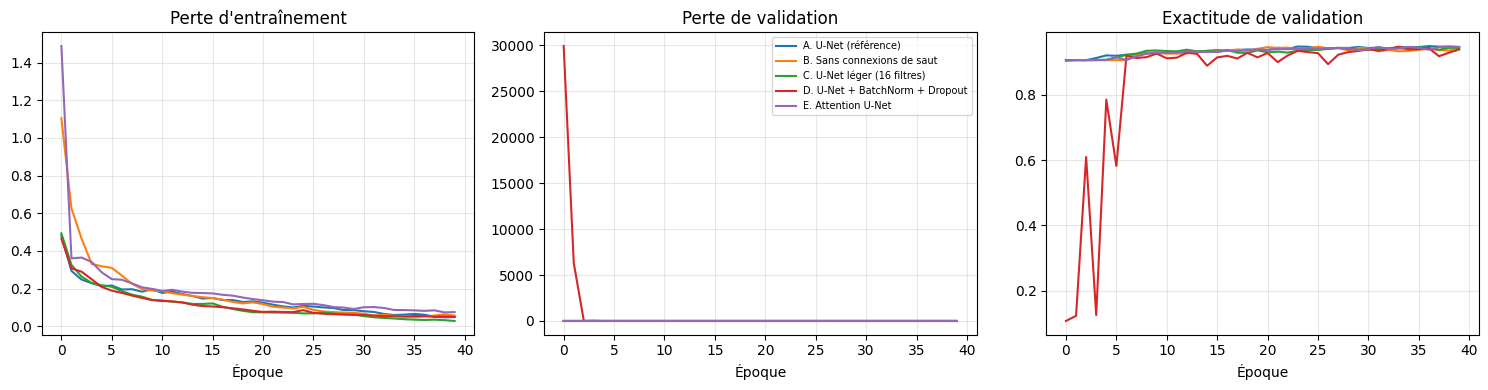

In [22]:
# Courbes d'apprentissage : perte et exactitude de validation, pour les cinq modèles
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for name, h in histories.items():
    axs[0].plot(h["loss"], label=name)
    axs[1].plot(h["val_loss"], label=name)
    axs[2].plot(h["val_accuracy"], label=name)
for ax, t in zip(axs, ["Perte d'entraînement", "Perte de validation", "Exactitude de validation"]):
    ax.set_title(t); ax.set_xlabel("Époque"); ax.grid(alpha=0.3)
axs[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_courbes.png", dpi=150); plt.show()

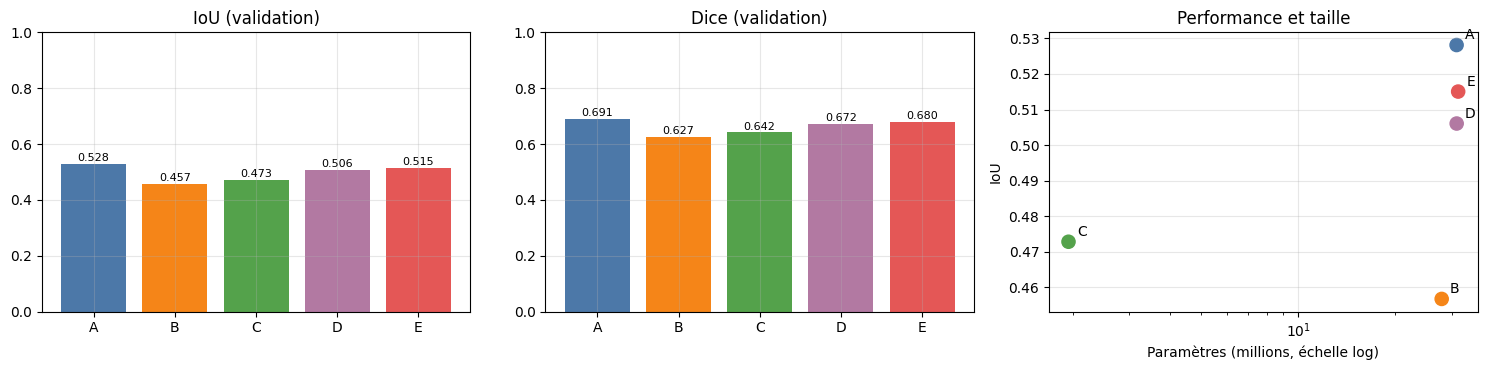

In [23]:
# IoU, Dice et rapport qualité/coût
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
short = [n.split(".")[0] for n in results.index]
axs[0].bar(short, results["IoU"], color=colors); axs[0].set_title("IoU (validation)"); axs[0].set_ylim(0, 1)
axs[1].bar(short, results["Dice"], color=colors); axs[1].set_title("Dice (validation)"); axs[1].set_ylim(0, 1)
for ax, col in zip(axs[:2], ["IoU", "Dice"]):
    for i, v in enumerate(results[col]): ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
axs[2].scatter(results["Paramètres"] / 1e6, results["IoU"], c=colors, s=90)
for n, x, yv in zip(short, results["Paramètres"] / 1e6, results["IoU"]): axs[2].annotate(n, (x, yv), textcoords="offset points", xytext=(6, 4))
axs[2].set_xscale("log"); axs[2].set_xlabel("Paramètres (millions, échelle log)"); axs[2].set_ylabel("IoU"); axs[2].set_title("Performance et taille")
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_iou.png", dpi=150); plt.show()

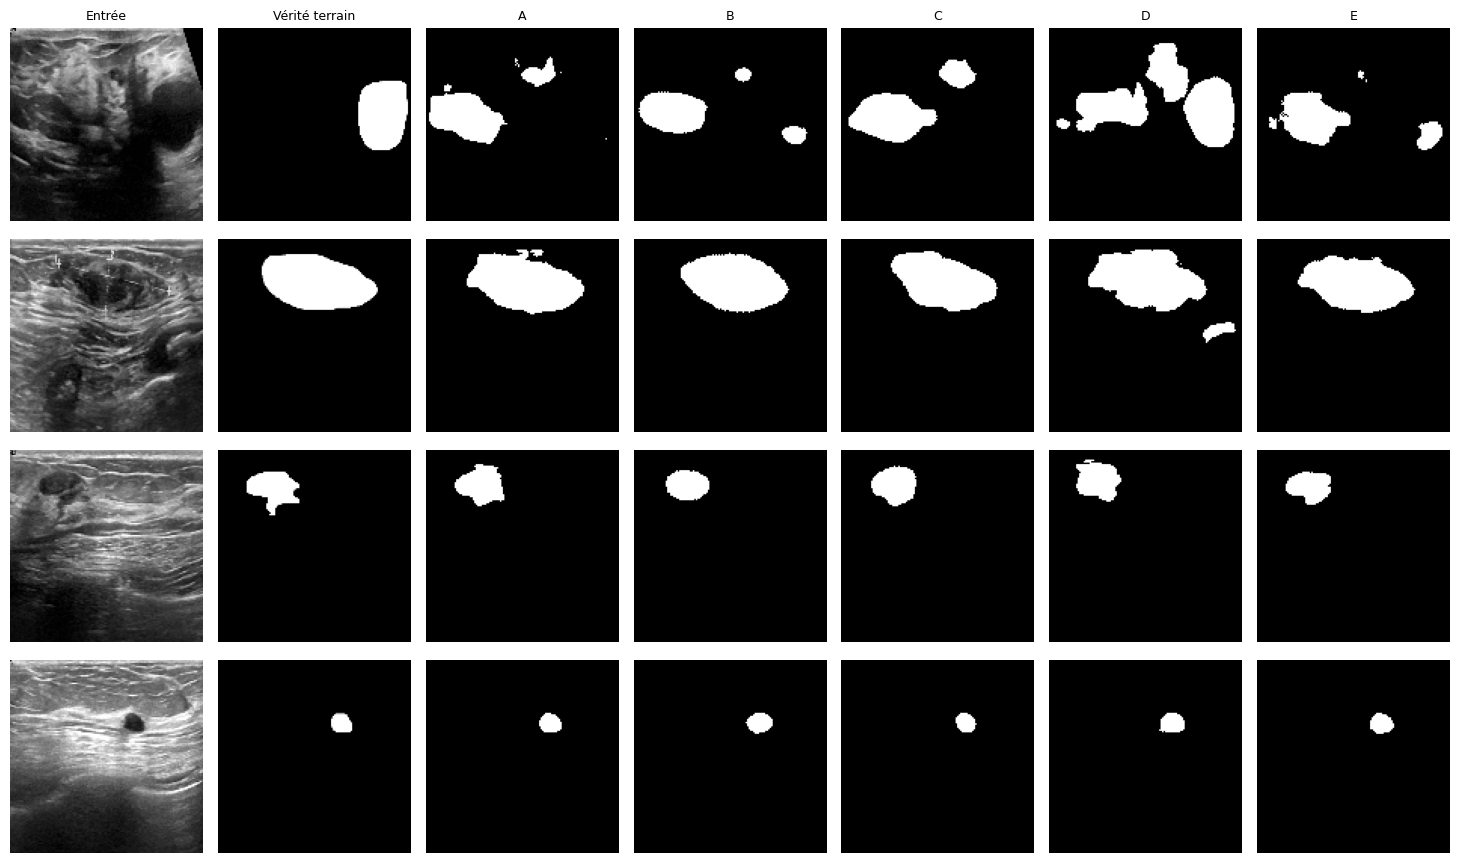

In [24]:
# Prédictions des cinq modèles sur les mêmes images de validation
idx = [0, 3, 6, 9]
cols = 2 + len(trained)
fig, axs = plt.subplots(len(idx), cols, figsize=(2.1 * cols, 2.2 * len(idx)))
for r, i in enumerate(idx):
    axs[r, 0].imshow(X_val[i], cmap="gray"); axs[r, 1].imshow(y_val[i], cmap="gray")
    for c, (name, m) in enumerate(trained.items(), start=2):
        p = m.predict(X_val[i:i + 1], verbose=0)[0] > 0.5
        axs[r, c].imshow(p, cmap="gray")
        if r == 0: axs[r, c].set_title(name.split(".")[0], fontsize=9)
    if r == 0: axs[r, 0].set_title("Entrée", fontsize=9); axs[r, 1].set_title("Vérité terrain", fontsize=9)
    for c in range(cols): axs[r, c].axis("off")
plt.tight_layout(); plt.savefig("fig_predictions.png", dpi=150); plt.show()

## 6. Lecture des résultats

La cellule suivante produit un commentaire chiffré à partir des résultats réels, sans rien supposer : elle classe les modèles et mesure, pour chaque variante, l'écart avec la référence.

Pour interpréter ces écarts, trois précautions s'imposent :

- **Un seul entraînement par modèle.** Les écarts de quelques millièmes d'IoU sont dans le bruit d'initialisation ; on ne conclut que sur des différences nettes.
- **Validation unique, réutilisée.** Le même ensemble de validation sert au suivi pendant l'entraînement et à la mesure finale, comme dans le tutoriel. Les scores sont donc légèrement optimistes ; une vraie évaluation réserverait un ensemble de test jamais utilisé.
- **Petit jeu de données.** Environ 650 images 128×128, redimensionnées depuis des échographies d'environ 500×500 : des détails fins sont perdus, et tous les modèles peuvent saturer à des valeurs proches.

In [25]:
ranking = results.sort_values("IoU", ascending=False)
print("Classement par IoU de validation :")
for rank, (name, row) in enumerate(ranking.iterrows(), 1):
    print(f"  {rank}. {name:<34} IoU = {row['IoU']:.4f} | Dice = {row['Dice']:.4f} | {int(row['Paramètres']):,} paramètres".replace(",", " "))

ref = results.loc["A. U-Net (référence)"]
print("\nÉcart avec le U-Net de référence (A) :")
for name, row in results.iterrows():
    if name.startswith("A."):
        continue
    d_iou = row["IoU"] - ref["IoU"]
    verdict = "écart net" if abs(d_iou) > 0.02 else "écart faible, probablement dans le bruit d'un seul entraînement"
    print(f"  {name:<34} IoU {d_iou:+.4f}  ({verdict}) | paramètres x{row['Paramètres'] / ref['Paramètres']:.2f} | durée x{row['Durée (min)'] / ref['Durée (min)']:.2f}")

best_eff = (results["IoU"] / (results["Paramètres"] / 1e6)).idxmax()
print(f"\nMeilleur rapport IoU par million de paramètres : {best_eff}")

Classement par IoU de validation :
  1. A. U-Net (référence)               IoU = 0.5281 | Dice = 0.6912 | 31 030 593 paramètres
  2. E. Attention U-Net                 IoU = 0.5150 | Dice = 0.6799 | 31 380 197 paramètres
  3. D. U-Net + BatchNorm + Dropout     IoU = 0.5061 | Dice = 0.6720 | 31 048 257 paramètres
  4. C. U-Net léger (16 filtres)        IoU = 0.4728 | Dice = 0.6420 | 1 940 817 paramètres
  5. B. Sans connexions de saut         IoU = 0.4567 | Dice = 0.6270 | 27 897 153 paramètres

Écart avec le U-Net de référence (A) :
  B. Sans connexions de saut         IoU -0.0715  (écart net) | paramètres x0.90 | durée x0.62
  C. U-Net léger (16 filtres)        IoU -0.0554  (écart net) | paramètres x0.06 | durée x0.34
  D. U-Net + BatchNorm + Dropout     IoU -0.0221  (écart net) | paramètres x1.00 | durée x1.10
  E. Attention U-Net                 IoU -0.0131  (écart faible, probablement dans le bruit d'un seul entraînement) | paramètres x1.01 | durée x0.99

Meilleur rapport IoU par m

## 7. Synthèse

Ce notebook a :

1. **complété le U-Net du tutoriel** : les `...` sont remplis (64-128-256-512-1024, puis 512-256-128-64, sortie 1×1 sigmoïde) et les neuf cartes de caractéristiques (quatre blocs d'encodeur, espace latent, quatre blocs de décodeur) sont visualisables avant et après l'entraînement ;
2. **généré quatre autres architectures** à partir d'une seule fonction de construction, en ne modifiant qu'un ingrédient à la fois (connexions de saut, largeur, normalisation et dropout, attention) ;
3. **calculé à la main** le nombre de paramètres et le coût en GMACs de chacune, puis vérifié ces valeurs contre Keras ;
4. **comparé les cinq modèles** dans des conditions identiques, avec des métriques adaptées au déséquilibre entre lésion et fond (IoU et Dice plutôt que l'exactitude).

Le rapport de synthèse comparative qui accompagne ce notebook reprend ces résultats, les tableaux et les figures générés ici (`fig_variantes.png`, `fig_params.png`, `fig_courbes.png`, `fig_iou.png`, `fig_predictions.png`, `resultats_comparaison.csv`).

In [26]:
from google.colab import files

# Étape 1 : Créer ou enregistrer votre fichier localement dans Colab
nom_fichier = "mon_fichier.txt"
with open(nom_fichier, "w") as f:
    f.write("Voici les résultats de ma cellule !")

# Étape 2 : Déclencher le téléchargement vers votre ordinateur
files.download(nom_fichier)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>